<a href="https://colab.research.google.com/github/CienciaDatosUdea/002_EstudiantesAprendizajeEstadistico/blob/main/semestre2026-2/Laboratorios/Laboratorio_13_Desicion_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **Laboratorio N°13: Árboles de Descisión**

**Curso:** Aprendizaje Estadistico 2026-2  
**Estudiante:** Jeronimo Lopez Gomez

------


## **Algoritmo CART (classification and regresion tree)**

Se busca entrenar un modelo para categorizar la información encontrando la frontera de desición, permite tener una mejor interpretabilidad que las redes neuronales dado que se puede tener una represetancion grafica del proceso de desiscion secuencial.

- ref https://www.youtube.com/watch?v=kqaLlte6P6o&ab_channel=CodificandoBits
- Hand on Machine learning 




Dado un conjunto de caracteristicas se establece una condición que realiza 
una particion binaria de los datos a clasificar repitiendo hasta encontrar 
particiones lo más homogenea posible.




In [1]:
from sklearn.datasets import make_classification
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.model_selection import train_test_split
#import graphviz
#from sklearn.tree import export_graphviz
import matplotlib.pyplot as plt
import numpy as np
from sklearn import tree

Se realiza un dataset de clasificación con 20 muestras, 2 características, 1 característica informativa y 0 características redundantes. Se establece una semilla aleatoria para reproducibilidad y se especifica que habrá un solo clúster por clase.

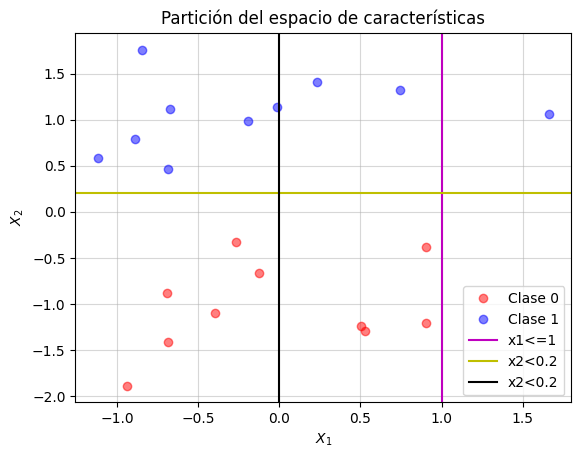

In [2]:
X0, y0 = make_classification(n_samples=20,
    n_features=2, n_redundant=0, n_informative=1, random_state=1, 
    n_clusters_per_class=1)

#Se establece el dominio de la frontera de decisión
x=np.arange(-2, 3,1)
x_,y_ = np.meshgrid(x,x)

fig, ax = plt.subplots()
ax.plot(X0[:,0][y0==0],X0[:,1][y0==0],"ro", alpha=0.5, label="Clase 0")
ax.plot(X0[:,0][y0==1],X0[:,1][y0==1],"bo", alpha=0.5, label="Clase 1")
#ax.plot(x_,y_,"k.")

ax.axvline(x = 1, color = 'm', label="x1<=1")
ax.axhline(y = 0.2, color = 'y', label="x2<0.2")
ax.axvline(x = 0.0, color = 'k', label="x2<0.2")
#plt.legend(loc=3)
plt.title("Partición del espacio de características")
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.legend(loc=4)
plt.grid(alpha=0.5)
plt.show()

- ### Gini index


$G = 1 - (PC_1)^2 - (PC_2)^2$

$PC_1$: Probablidad categoria 1 

$PC_2$: Probablidad categoria 2 

Si :

- $G=0$ nodos puros, datos que pertenecen a una sola categoría

- $G > 0$ son nodos con impurezas, con mas de una categoría


La partición purpura  y amarilla del gráfico anterior representan nodos puros.

Mientras que la linea negra define:

- 7 puntos son de color azul.

- 6 puntos de color rojo.

$G = 1 - (7/13)^{2} - (6/13)^{2}$

mientrás que la ponderacion viene dada por:

$m = (7/20+7/20)=7/10$



No:

$G=1-(3/7)^{2}-(4/7)^{2}$ 

$m = (3/20+4/20)$


Finalmente la funcion de coste, asocida al nodo padre:

$J(k, t_k) = \frac{m_{left}}{m} G_{left} + \frac{m_{right}}{m} G_{right} $

----



**Algoritmo**
1. Calcular todos los posibles condiciones. 
2. Calcular los indices de Gini.
3. Encontrar la funcion de coste 
4. Escoger la menor funcion de coste 
5. Repetir.

----

----

## **Desarrollo del Laboratorio**

#### 1. Importar el conjunto de datos Iris

Iris contiene **150 flores**, descritas mediante cuatro medidas en centímetros (longitud y ancho del sépalo y del pétalo). El objetivo es clasificar cada flor en una de tres especies.

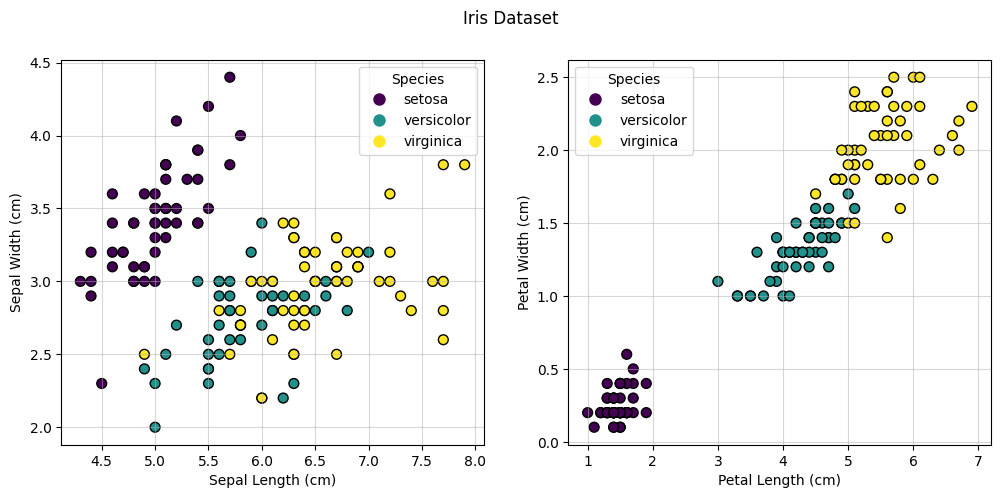

In [2]:
SEED = 42
iris = load_iris()
X, y = iris.data, iris.target


#Graficamos los datos de iris en un scatter plot,
# usando las dos primeras características (sepal length y sepal width)
# para el primer gráfico y las dos últimas características (petal length y petal width
# para el segundo gráfico. Cada punto se colorea según su clase (especie de iris).
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', edgecolor='k', s=50)
ax[0].legend(handles=[plt.Line2D([0], [0], marker='o', color='w', label=iris.target_names[i],
                          markerfacecolor=plt.cm.viridis(i / 2), markersize=10)
                          for i in range(3)],
                          title="Species")
ax[0].set_ylabel("Sepal Width (cm)")
ax[0].set_xlabel("Sepal Length (cm)")
ax[0].grid(alpha=0.5)

ax[1].scatter(X[:, 2], X[:, 3], c=y, cmap='viridis', edgecolor='k', s=50)
ax[1].legend(handles=[plt.Line2D([0], [0], marker='o', color='w', label=iris.target_names[i],
                          markerfacecolor=plt.cm.viridis(i / 2), markersize=10)
                          for i in range(3)],
                          title="Species")
plt.suptitle("Iris Dataset")
ax[1].set_ylabel("Petal Width (cm)")
ax[1].set_xlabel("Petal Length (cm)")
ax[1].grid(alpha=0.5)
plt.show()

#### 2. Primera Intuición

Calculemos las principales estadísticas que nos pueden ayudar a encontrar las primeras relaciones e inferir sobre la correlación entre variables

In [5]:
df_iris = pd.DataFrame(X, columns=iris.feature_names)
df_iris["species"] = iris.target_names[y]

print("primeras 5 filas del dataset:")
display(df_iris.head())

print("---"*20)
print("\nEstadísticas descriptivas:")
display(df_iris.describe().round(2))
print("\nMuestras por especie:")
print(df_iris["species"].value_counts())

primeras 5 filas del dataset:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


------------------------------------------------------------

Estadísticas descriptivas:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50



Muestras por especie:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


El conjunto de datos contiene 150 observaciones distribuidas uniformemente entre las tres especies de Iris, con 50 muestras por especie.

Observamos que la longitud del pétalo presenta una variabilidad considerable (desviación estándar de 1.77 cm), mientras que las dimensiones del sépalo muestran una dispersión menor.

En las primeras observaciones de setosa encontramos pétalos relativamente pequeños. Además de acuerdo a las figuras anteriores se plantea que la longitud y el ancho del pétalo podrían ser características importantes para distinguir las versicolor de las otras 2 especies. 

#### 3. Dividir el dataset en entrenamiento y prueba

Separamos el 80 % para entrenamiento y el 20 % para prueba. `stratify=y` conserva aproximadamente la misma proporción de especies en ambos conjuntos.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("Clases en entrenamiento:", np.bincount(y_train))
print("Clases en prueba:", np.bincount(y_test))

Entrenamiento: (120, 4) | Prueba: (30, 4)
Clases en entrenamiento: [40 40 40]
Clases en prueba: [10 10 10]


#### 4. Implementación de `DecisionTreeClassifier`

Entrenamos el árbol CART (classification and regression tree) haciendo uso del indice de Gini. Después evaluamos su clasificación en los datos que se reservaron para prueba. El árbol se mantiene sin una profundidad máxima predefinida para observar su estructura aprendida completa.

Exactitud en entrenamiento: 100.00%
Exactitud en prueba: 93.33%

Reporte de clasificación:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



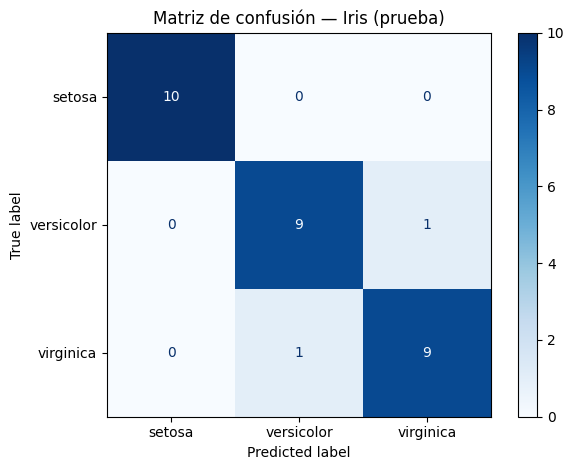

In [10]:
#Importamos las librerías para hacer evaluación del modelo
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

#Arbol de decisión con criterio de Gini
clf = DecisionTreeClassifier(criterion="gini", random_state=SEED)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print(f"Exactitud en entrenamiento: {clf.score(X_train, y_train):.2%}")
print(f"Exactitud en prueba: {accuracy_score(y_test, y_pred):.2%}")
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

#Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=iris.target_names, cmap="Blues"
)

plt.title("Matriz de confusión — Iris (prueba)")
plt.tight_layout()
plt.show()

De acuerdo con la matriz de confusión, el árbol logro clasificar correctamente las especies de setosa, mientras que para versicolor y virginica se tuvo un margen de error del 0.90, de cada 10 individuos, clasifica mal 1 de estos.

#### 5.Gráfico del árbol de decisión

Cada nodo muestra una regla de división sobre una característica (por ejemplo, un umbral de longitud de pétalo). Las ramas representan las decisiones y las hojas contienen la clasificación final. `samples` es el número de observaciones de entrenamiento que llegan a cada nodo y `value` describe su distribución entre clases.

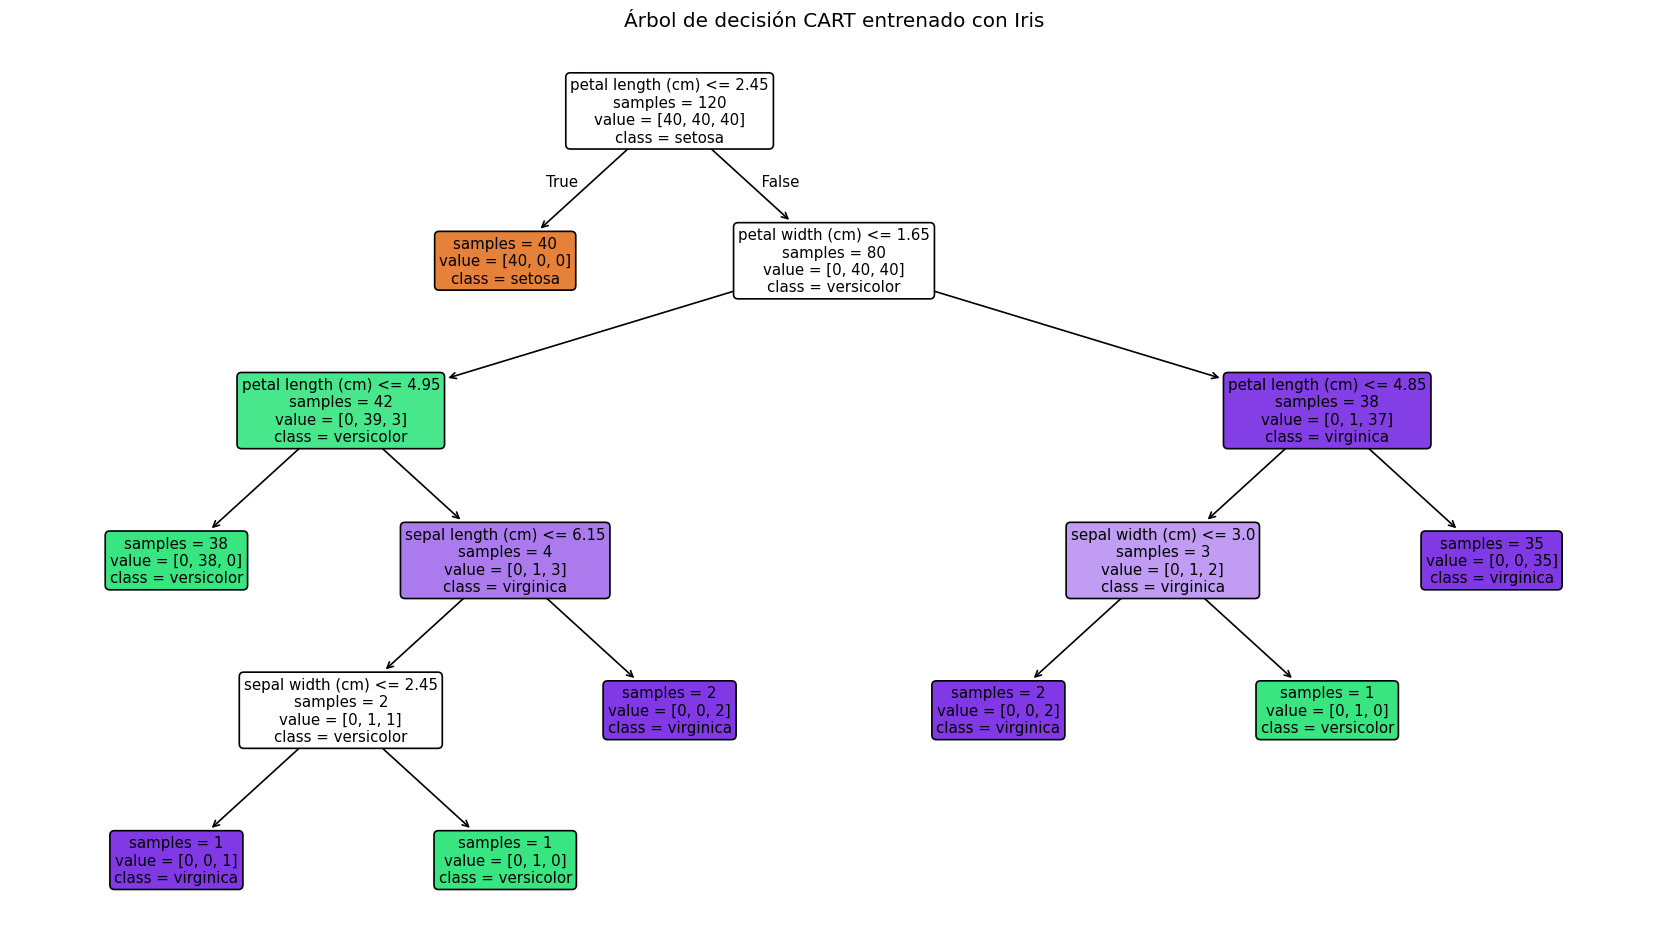

Profundidad del árbol: 5
Número de hojas: 8


In [11]:
fig, ax = plt.subplots(figsize=(14, 8), dpi=120)
tree.plot_tree(
    clf,
    class_names=iris.target_names,
    feature_names=iris.feature_names,
    impurity=False,
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax
)
plt.title("Árbol de decisión CART entrenado con Iris")
plt.tight_layout()
plt.show()

print("Profundidad del árbol:", clf.get_depth())
print("Número de hojas:", clf.get_n_leaves())

El árbol CART utiliza principalmente la longitud y el ancho del pétalo para clasificar las especies de Iris, lo que respalda nuestra intuición inicial.

La primera división se realiza con una longitud del pétalo de 2.45 cm, permitiendo identificar correctamente las 40 muestras de setosa del conjunto de entrenamiento.

Por otra parte, la separación entre versicolor y virginica requiere más divisiones, principalmente mediante las dimensiones del pétalo y, en algunos casos, del sépalo. Esto sugiere que ambas especies presentan características más similares.

En general, el árbol logra separar las tres especies, aunque necesita reglas adicionales para clasificar algunas observaciones de versicolor y virginica.

#### 6. Características más importantes

`feature_importances_` mide la contribución relativa de cada característica a la reducción de impureza dentro de este árbol. Una importancia alta indica que la característica fue útil para las divisiones de este modelo.

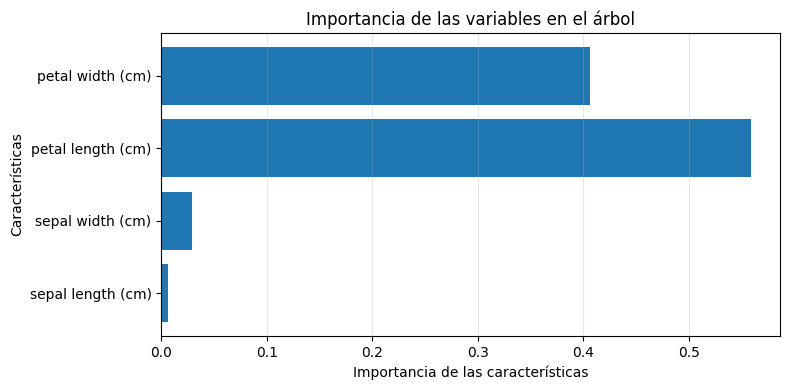

petal length (cm): 0.559
petal width (cm): 0.406
sepal width (cm): 0.029
sepal length (cm): 0.006


In [13]:
caract = iris.data.shape[1]
importancias = clf.feature_importances_

plt.figure(figsize=(8, 4))
plt.barh(range(caract), importancias)
plt.yticks(np.arange(caract), iris.feature_names)
plt.xlabel("Importancia de las características")
plt.ylabel("Características")
plt.title("Importancia de las variables en el árbol")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

for nombre, imp in sorted(zip(iris.feature_names, importancias), key=lambda p: p[1], reverse=True):
    print(f"{nombre}: {imp:.3f}")

#### 7. Graficar las fronteras de decisión

Se entrena un árbol distinto para cada par de características y representamos sus regiones de clasificación. Utilizamos el dataset Iris completo, ya la validación se realizó anteriormente.

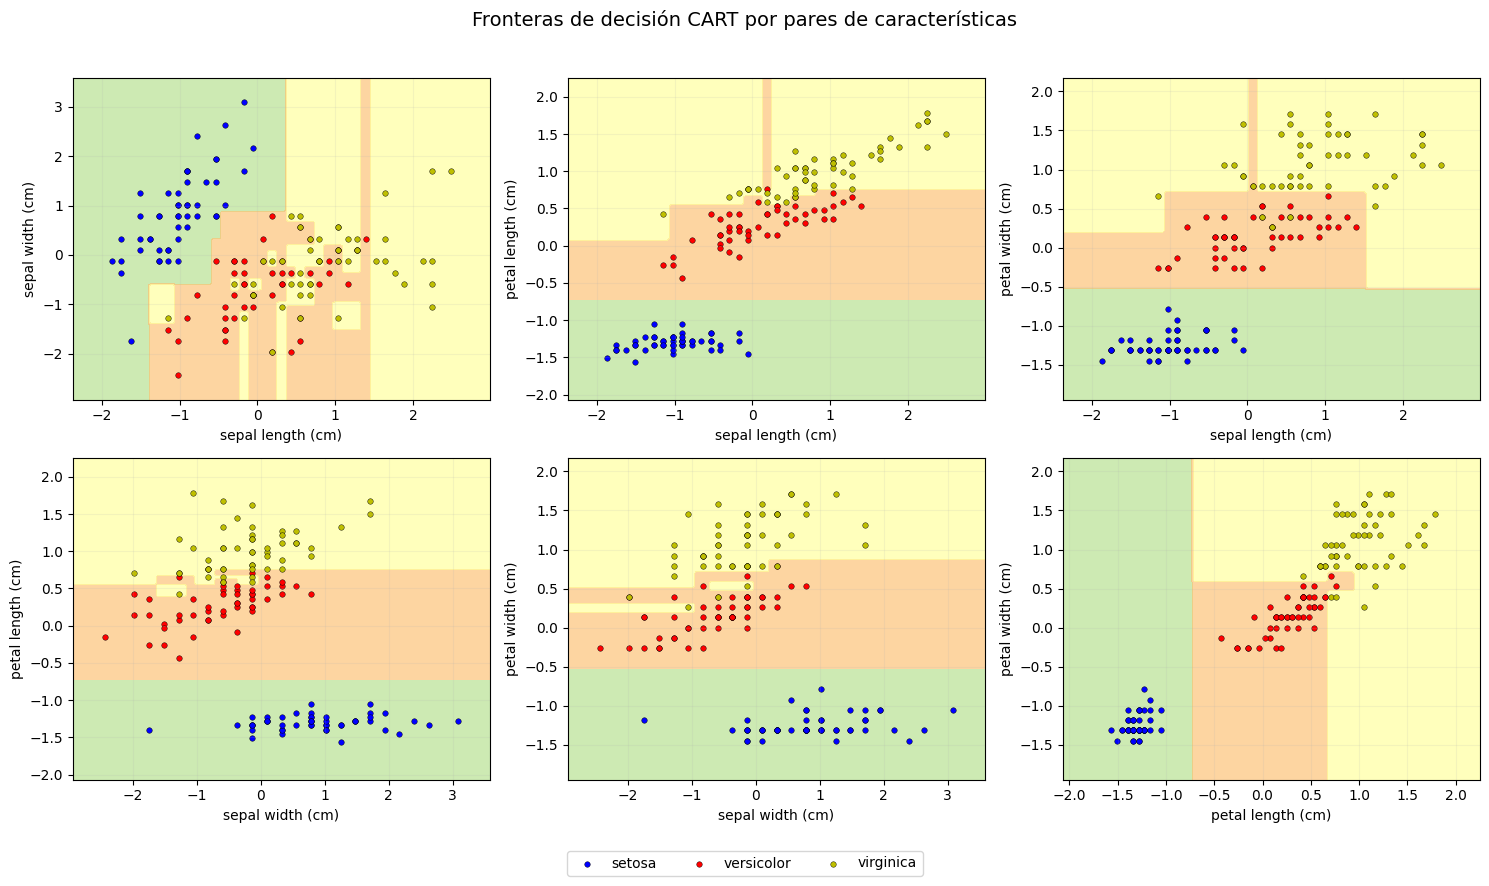

In [16]:
#Se establecen 3 clases, así como el paso de la malla para graficar las fronteras de decisión
n_classes = 3
plot_colors = "bry"
plot_step = 0.04

# Almacenar los modelos y datos de cada par de características
modelos_pares = []
datos_pares = []

#Se definen los pares de características a utilizar para entrenar árboles independientes
pares = [[0, 1], [0, 2], [0, 3], [1, 2], [1, 3], [2, 3]]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for pairidx, pair in enumerate(pares):
    X_par = iris.data[:, pair]
    y_par = iris.target

    # Estandarización del par para su visualización
    mean = X_par.mean(axis=0)
    std = X_par.std(axis=0)
    X_par = (X_par - mean) / std

    # Cada par de variables se utiliza para entrenar un árbol independiente
    clf_par = DecisionTreeClassifier(random_state=SEED).fit(X_par, y_par)

    # Guardamos el modelo y los datos utilizados
    modelos_pares.append(clf_par)
    datos_pares.append((X_par, y_par))

    x_min, x_max = X_par[:, 0].min() - 0.5, X_par[:, 0].max() + 0.5
    y_min, y_max = X_par[:, 1].min() - 0.5, X_par[:, 1].max() + 0.5
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, plot_step),
        np.arange(y_min, y_max, plot_step)
    )
    Z = clf_par.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax = axes.flat[pairidx]
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5, 2.5], cmap=plt.cm.Paired, alpha=0.65)
    for i, color in enumerate(plot_colors):
        idx = y_par == i
        ax.scatter(
            X_par[idx, 0], X_par[idx, 1],
            c=color, label=iris.target_names[i], s=16, edgecolors="k", linewidths=0.3
        )

    ax.set_xlabel(iris.feature_names[pair[0]])
    ax.set_ylabel(iris.feature_names[pair[1]])
    ax.grid(alpha=0.15)

fig.suptitle("Fronteras de decisión CART por pares de características", fontsize=14)
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, bbox_to_anchor=(0.5, 0.01))
fig.tight_layout(rect=[0, 0.06, 1, 0.96])
plt.show()

In [17]:
#Cuantifiquemos los errores de clasificación para cada par de características

resultados = []

for pair, modelo, (X_par, y_par) in zip(pares, modelos_pares, datos_pares):

    # Predicciones de los modelos ya entrenados
    y_pred = modelo.predict(X_par)

    exactitud = accuracy_score(y_par, y_pred)
    error = 1 - exactitud

    resultados.append({
        "Características": " / ".join(iris.feature_names[i] for i in pair),
        "Exactitud (%)": exactitud * 100,
        "Error (%)": error * 100,
        "Errores": np.sum(y_par != y_pred)
    })

df_resultados = pd.DataFrame(resultados)
display(df_resultados.round(2))

,Características,Exactitud (%),Error (%),Errores
0,sepal length (cm) / sepal width (cm),92.67,7.33,11
1,sepal length (cm) / petal length (cm),99.33,0.67,1
2,sepal length (cm) / petal width (cm),97.33,2.67,4
3,sepal width (cm) / petal length (cm),98.67,1.33,2
4,sepal width (cm) / petal width (cm),98.00,2.00,3
5,petal length (cm) / petal width (cm),99.33,0.67,1


Los resultados muestran que las combinaciones longitud del sépalo con longitud del pétalo y longitud del petalo con su ancho presentan la mayor exactitud, con un 99.33 %, equivalente a una sola clasificación incorrecta de las 150 muestras.

Por el contrario, la combinación de longitud y ancho del sépalo presenta el mayor error, con 7.33 %, correspondiente a 11 muestras, lo que sugiere que estas variables por sí solas permiten una menor separación entre las especies.

En general, observamos que las combinaciones que incluyen características del pétalo presentan mejores resultados, respaldando nuestra intuición inicial sobre su importancia para la clasificación.